# Multilingual Language Detection

In [33]:
from pathlib import Path
import re, unicodedata, json, time
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/processed/language_dataset.csv").exists():
    ROOT = Path.cwd().parent
DATA_PATH = ROOT / "data/processed/language_dataset.csv"
MODEL_PATH = ROOT / "models/language_detector_pipeline.joblib"


## 1. Load and inspect the provided dataset

In [34]:
df = pd.read_csv(DATA_PATH)
# Support the consolidated CSV schema while keeping the notebook self-contained.
text_col = next((c for c in df.columns if c.lower() == "cleaned_text"), next(c for c in df.columns if c.lower() == "text"))
label_col = next(c for c in df.columns if c.lower() == "language")
df = df[[text_col, label_col]].rename(columns={text_col: "text", label_col: "language"})
df = df.dropna().copy()
df["language"] = df["language"].astype(str).str.strip().str.title()
df["language"] = df["language"].replace({"Portugese":"Portuguese", "Portugeese":"Portuguese", "Sweedish":"Swedish"})
print(f"Rows: {len(df):,}; classes: {df.language.nunique()}")
df.language.value_counts()

Rows: 32,098; classes: 28


language
English       2382
French        1995
Spanish       1810
Portuguese    1733
Russian       1684
Swedish       1661
Dutch         1535
Arabic        1529
Turkish       1470
Tamil         1443
Hindi         1051
Thai          1000
Japanese      1000
Urdu          1000
Chinese       1000
Korean        1000
Persian       1000
Romanian      1000
Estonian       999
Pushto         993
Indonesian     974
Latin          953
Italian        692
Malayalam      589
German         462
Danish         421
Kannada        365
Greek          357
Name: count, dtype: int64

## 2. Unicode-aware text normalization

In [35]:
def clean_text(value):
    if not isinstance(value, str):
        return ""
    value = unicodedata.normalize("NFKC", value)
    value = re.sub(r"https?://\S+|www\.\S+|\S+@\S+|\[\d+\]", " ", value)
    value = re.sub(r"['\"`.,!?;:()\[\]{}<>/\\|@#$%^&*~+=_\-0-9]", " ", value)
    kept = "".join(ch.lower() if unicodedata.category(ch).startswith(("L", "M")) else " " for ch in value)
    return re.sub(r"\s+", " ", kept).strip()

df["cleaned_text"] = df.text.astype(str).str.strip()
df = df[df.cleaned_text.str.len() >= 3].reset_index(drop=True)
print(f"Usable unique texts: {len(df):,}; classes: {df.language.nunique()}")

Usable unique texts: 32,098; classes: 28


## 3. Stratified holdout split

The test portion is kept out of model fitting and parameter selection. Since the prior project benchmark appears to have used this same dataset, this split is useful for an internal check but is not independent external validation.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    df.cleaned_text, df.language, test_size=0.20, random_state=42, stratify=df.language
)
print(f"Train: {len(X_train):,}; test: {len(X_test):,}")

Train: 25,678; test: 6,420


## 4. Train the Logistic Regression classifier

The training workflow uses Logistic Regression only, as required by the project syllabus.

In [37]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 5), max_features=50000, sublinear_tf=True)),
    ("classifier", LogisticRegression(C=5.0, max_iter=600, random_state=42, solver="lbfgs")),
])
start = time.time()
model.fit(X_train, y_train)
print(f"Training completed in {time.time()-start:.1f}s")

Training completed in 60.6s


## 5. Held-out evaluation

In [38]:
y_pred = model.predict(X_test)
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_precision": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "weighted_precision": float(precision_score(y_test, y_pred, average="weighted", zero_division=0)),
    "macro_recall": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
}
print(json.dumps(metrics, indent=2))
print("\nPer-language report:")
print(classification_report(y_test, y_pred, zero_division=0))
if metrics["accuracy"] >= 0.99:
    print("Held-out accuracy exceeded 99%.")
else:
    print("Held-out accuracy is below 99%; report the measured result.")

{
  "accuracy": 0.983177570093458,
  "macro_precision": 0.9874909005551157,
  "weighted_precision": 0.9840949712363574,
  "macro_recall": 0.9808710725091132,
  "macro_f1": 0.9839641554585176
}

Per-language report:
              precision    recall  f1-score   support

      Arabic       0.99      1.00      1.00       306
     Chinese       0.98      0.96      0.97       200
      Danish       0.98      0.94      0.96        84
       Dutch       1.00      0.98      0.99       307
     English       0.89      1.00      0.94       476
    Estonian       0.99      0.94      0.97       200
      French       0.98      0.99      0.98       399
      German       0.97      0.97      0.97        92
       Greek       1.00      1.00      1.00        71
       Hindi       1.00      0.98      0.99       210
  Indonesian       1.00      0.97      0.99       195
     Italian       0.96      0.97      0.96       138
    Japanese       1.00      0.95      0.98       200
     Kannada       1.00     

## 6. Inspect errors

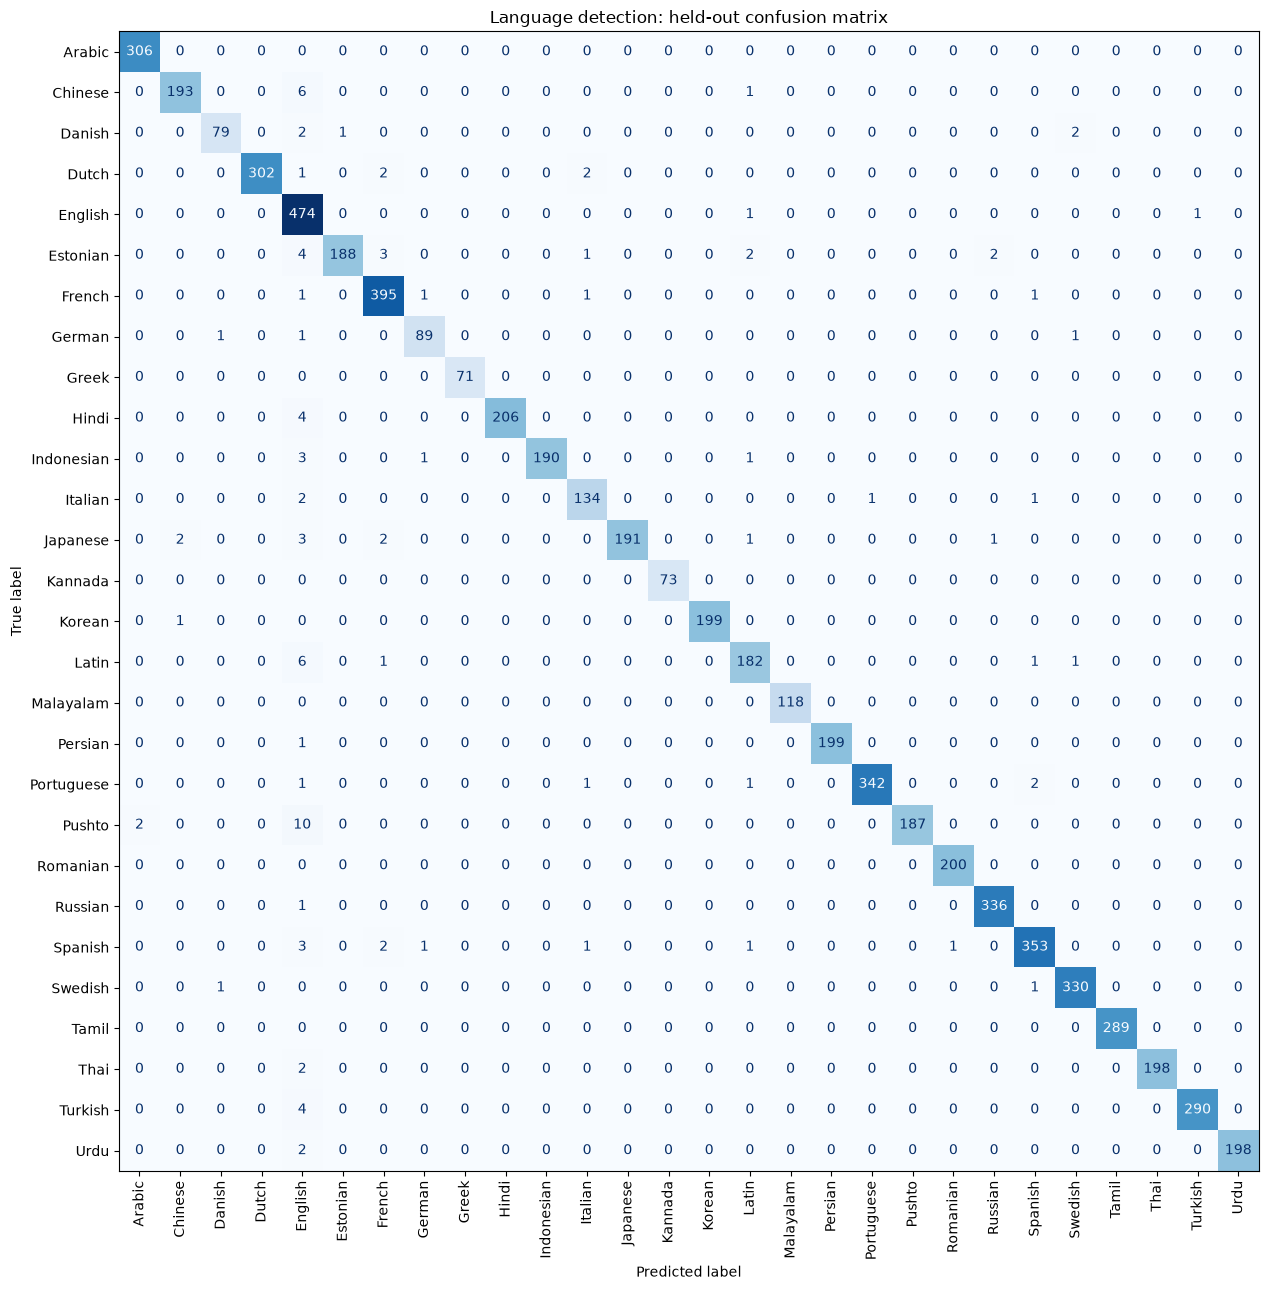

In [39]:
fig, ax = plt.subplots(figsize=(15, 13))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Language detection: held-out confusion matrix")
plt.tight_layout()
plt.show()

## 7. Save the trained model for FastAPI

The saved pipeline includes its fitted vectorizer and classifier. The backend performs the same text normalization before inference.

In [40]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_PATH, compress=3)
metadata = {"selected_model":"Logistic Regression", "num_languages":int(df.language.nunique()),
            "supported_languages":sorted(df.language.unique().tolist()), "total_samples":int(len(df)),
            "train_samples":int(len(X_train)), "test_samples":int(len(X_test)),
            "best_model_metrics":metrics, "created_at":time.strftime("%Y-%m-%d %H:%M:%S")}
(ROOT / "models/model_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Saved model to {MODEL_PATH}")

Saved model to /Users/prantordas/Desktop/main_projects/language-predictor-using-ML/models/language_detector_pipeline.joblib
